# Ahmedabad Used Two-Wheeler Price Analysis
## Seaborn Session 6 – Jointplot

Analysis of 400 fictional used two-wheeler listings using scatter, hexbin and KDE jointplots.

Task 1: Generate 400 two-wheeler listings

   age_years ownership     km_driven     price_inr
0          7     First  52746.787154  29068.985950
1          4    Second  29564.373081  44967.039155
2         11     First  85038.030379   8000.000000
3          8     First  59680.046152  25509.364772
4          5    Second  40242.608140  39533.816111
Total Listings: 400


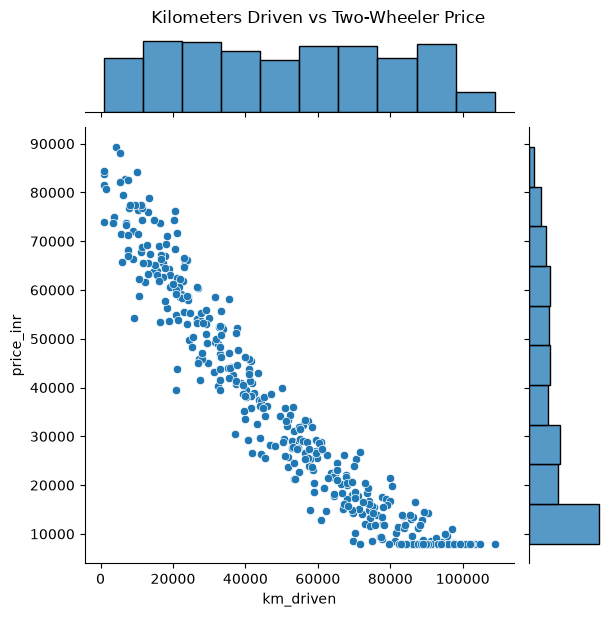

In [4]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

age_years = np.random.randint(1, 13, 400)

ownership = np.random.choice(
    ["First", "Second"],
    size=400,
    p=[0.7, 0.3]
)

km_driven = age_years * 8000 + np.random.normal(
    0, 5000, 400
)

km_driven = np.maximum(km_driven, 1000)

price_inr = 90000 * np.exp(
    -0.12 * age_years
) - 0.2 * km_driven + np.random.normal(
    0, 4000, 400
)

price_inr = np.where(
    ownership == "Second",
    price_inr * 0.9,
    price_inr
)

price_inr = np.maximum(price_inr, 8000)

df = pd.DataFrame({
    "age_years": age_years,
    "ownership": ownership,
    "km_driven": km_driven,
    "price_inr": price_inr
})

df.to_csv("two_wheeler_listings.csv", index=False)

print(df.head())
print("Total Listings:", len(df))

g = sns.jointplot(
    data=df,
    x="km_driven",
    y="price_inr",
    kind="scatter"
)

g.figure.suptitle(
    "Kilometers Driven vs Two-Wheeler Price",
    y=1.02
)

plt.show()


Task 2: Hexbin jointplot

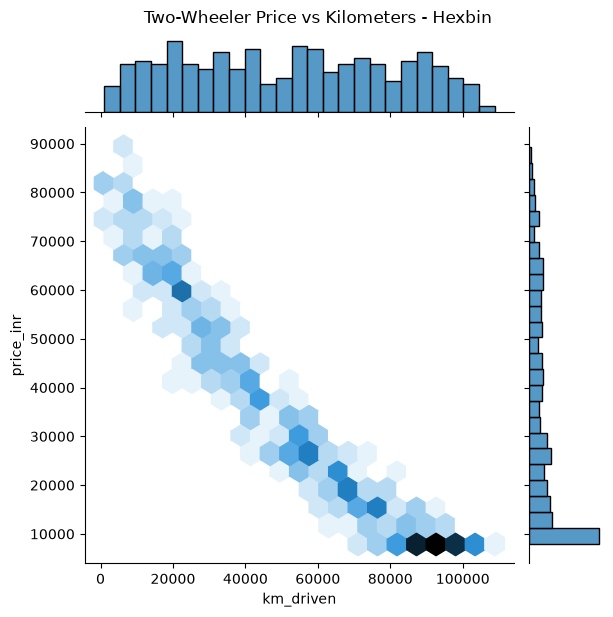

Hexbin chart saved successfully!


In [5]:

g = sns.jointplot(
    data=df,
    x="km_driven",
    y="price_inr",
    kind="hex",
    joint_kws={"gridsize": 20},
    marginal_kws={"bins": 25}
)

g.figure.suptitle(
    "Two-Wheeler Price vs Kilometers - Hexbin",
    y=1.02
)

g.savefig("two_wheeler_hex.png", dpi=150)

plt.show()

print("Hexbin chart saved successfully!")


Task 3: KDE jointplot by ownership

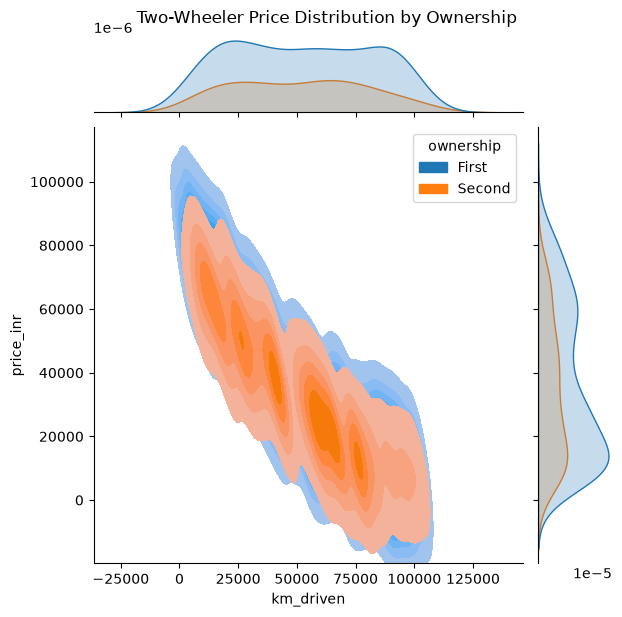

KDE jointplot saved successfully!


In [6]:

g = sns.jointplot(
    data=df,
    x="km_driven",
    y="price_inr",
    kind="kde",
    fill=True,
    hue="ownership"
)

g.figure.suptitle(
    "Two-Wheeler Price Distribution by Ownership",
    y=1.02
)

g.savefig("two_wheeler_kde.png", dpi=150)

plt.show()

print("KDE jointplot saved successfully!")


Task 4: Final jointplot and correlations

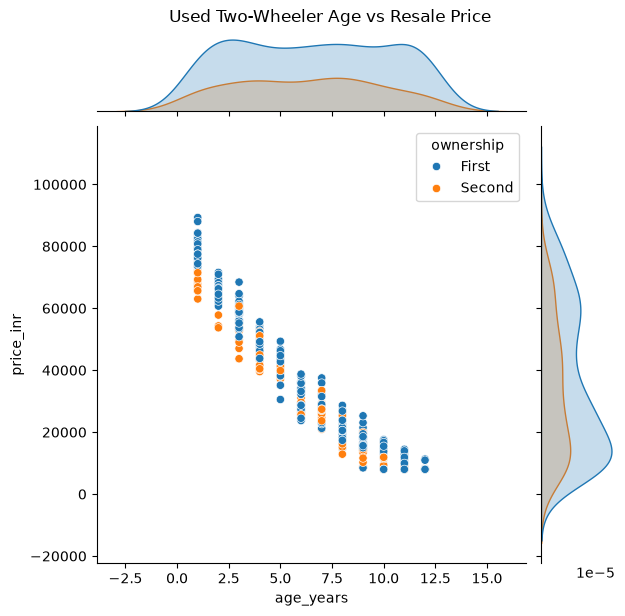

PEARSON CORRELATION REPORT
----------------------------------------
Age vs Price Correlation: -0.965
KM Driven vs Price Correlation: -0.958
Session 6 completed successfully!


In [7]:

g = sns.jointplot(
    data=df,
    x="age_years",
    y="price_inr",
    kind="scatter",
    hue="ownership",
    height=6
)

g.figure.suptitle(
    "Used Two-Wheeler Age vs Resale Price",
    y=1.02
)

g.savefig("two_wheeler_final_joint.png", dpi=150)

plt.show()

age_corr = df["age_years"].corr(df["price_inr"])

km_corr = df["km_driven"].corr(df["price_inr"])

print("PEARSON CORRELATION REPORT")
print("-" * 40)

print(
    "Age vs Price Correlation:",
    round(age_corr, 3)
)

print(
    "KM Driven vs Price Correlation:",
    round(km_corr, 3)
)

print("Session 6 completed successfully!")
